# 🌊 Análisis Exploratorio de Reseñas Turísticas — La Paz, BCS
**Dataset:** `la_paz.csv` | **Columnas:** `lugar`, `estrellas`, `texto`

Este notebook realiza un EDA completo de las variables estructurales y un análisis de texto con limpieza, lematización y nubes de palabras.

In [2]:
# ── INSTALACIÓN DE DEPENDENCIAS (ejecutar solo si es necesario) ──────────────
# Descomenta las líneas siguientes si alguna librería no está instalada:
# !pip install wordcloud
# !pip install nltk

# ── IMPORTS GENERALES ────────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import re
import string
from collections import Counter

import nltk
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer          # lematización ligera (stemmer)

from wordcloud import WordCloud

# ── DESCARGAS DE NLTK (solo la primera vez) ──────────────────────────────────
nltk.download('stopwords', quiet=True)
nltk.download('punkt',     quiet=True)

# ── ESTILO GLOBAL DE GRÁFICAS ─────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi'      : 130,
    'axes.spines.top' : False,
    'axes.spines.right': False,
    'font.family'     : 'DejaVu Sans',
})
PALETTE   = 'Blues_d'          # paleta principal
COLOR_POS = '#2196F3'          # azul para positivas
COLOR_NEG = '#EF5350'          # rojo para negativas

print('✅ Librerías cargadas correctamente.')

✅ Librerías cargadas correctamente.


---
## PARTE 1 — Análisis Exploratorio de Columnas Estructurales (`lugar` y `estrellas`)

### 1.1 · Carga de datos e inspección inicial

In [ ]:
# ── CARGA DEL DATASET ─────────────────────────────────────────────────────────
# Se especifica encoding='utf-8-sig' para eliminar el BOM (\ufeff) que
# suele aparecer en CSVs exportados desde Excel.
df = pd.read_csv('../data/puerto_vallarta_reviews.csv', encoding='utf-8-sig')

print(f'Shape del DataFrame: {df.shape}  →  {df.shape[0]:,} filas × {df.shape[1]} columnas')
df.head(10)

Shape del DataFrame: (8740, 3)  →  8,740 filas × 3 columnas


,lugar,estrellas,texto
0,catedral_la_paz,5,excelente lugar para orar
1,catedral_la_paz,5,esta muy bien conservada y llena de historia
2,catedral_la_paz,5,small church was getting a little face up when...
3,catedral_la_paz,5,es un lugar que se debe visitar
4,catedral_la_paz,5,muy linda y el padre explicar muy bien
5,catedral_la_paz,5,preciosa la iglesia
6,catedral_la_paz,5,good place to see
7,catedral_la_paz,5,muy bonita la catedral
8,catedral_la_paz,5,hermosos sitio
9,catedral_la_paz,5,pretty church definitely worth taking a look


In [7]:
# ── INFORMACIÓN GENERAL DE TIPOS Y NULOS ─────────────────────────────────────
print('=== df.info() ===')
df.info()
print()

print('=== Valores nulos por columna ===')
nulos = df.isnull().sum()
print(nulos)
print(f'\nTotal de filas con al menos un nulo: {df.isnull().any(axis=1).sum()}')

=== df.info() ===
<class 'pandas.DataFrame'>
RangeIndex: 8740 entries, 0 to 8739
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   lugar      8740 non-null   str  
 1   estrellas  8740 non-null   int64
 2   texto      8740 non-null   str  
dtypes: int64(1), str(2)
memory usage: 205.0 KB

=== Valores nulos por columna ===
lugar        0
estrellas    0
texto        0
dtype: int64

Total de filas con al menos un nulo: 0


In [8]:
# ── ESTADÍSTICAS DESCRIPTIVAS ─────────────────────────────────────────────────
# Para columnas numéricas: estrellas
# Para columnas categóricas: lugar, texto
print('=== Estadísticas numéricas ===')
display(df.describe())

print('\n=== Estadísticas categóricas ===')
display(df.describe(include='object'))

=== Estadísticas numéricas ===


,estrellas
count,8740.000000
mean,4.759725
std,0.645690
min,1.000000
25%,5.000000
50%,5.000000
75%,5.000000
max,5.000000



=== Estadísticas categóricas ===


C:\Users\default.LAPTOP-KBBOSBHD\AppData\Local\Temp\ipykernel_40972\1293731465.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include='object'))


,lugar,texto
count,8740,8740
unique,6,8626
top,malecon_la_paz,Excelente lugar
freq,4305,6


In [9]:
# ── MANEJO DE NULOS ───────────────────────────────────────────────────────────
# Eliminamos filas donde 'texto' o 'estrellas' sean nulos, ya que son
# las variables principales del análisis.
filas_antes = len(df)
df.dropna(subset=['texto', 'estrellas'], inplace=True)
filas_despues = len(df)

# Nos aseguramos de que estrellas sea entero
df['estrellas'] = df['estrellas'].astype(int)
# Reseteamos el índice tras la limpieza
df.reset_index(drop=True, inplace=True)

print(f'Filas eliminadas por nulos: {filas_antes - filas_despues}')
print(f'Filas restantes: {len(df):,}')

Filas eliminadas por nulos: 0
Filas restantes: 8,740


### 1.2 · Cantidad de reseñas por lugar

C:\Users\default.LAPTOP-KBBOSBHD\AppData\Local\Temp\ipykernel_40972\3430366819.py:29: UserWarning: Glyph 128205 (\N{ROUND PUSHPIN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\default.LAPTOP-KBBOSBHD\AppData\Local\Temp\ipykernel_40972\3430366819.py:30: UserWarning: Glyph 128205 (\N{ROUND PUSHPIN}) missing from font(s) DejaVu Sans.
  plt.savefig('01_resenas_por_lugar.png', bbox_inches='tight')
c:\Users\default.LAPTOP-KBBOSBHD\Documents\visualizacion_de_la_informacion\Analisis_destino_turismo\venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128205 (\N{ROUND PUSHPIN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


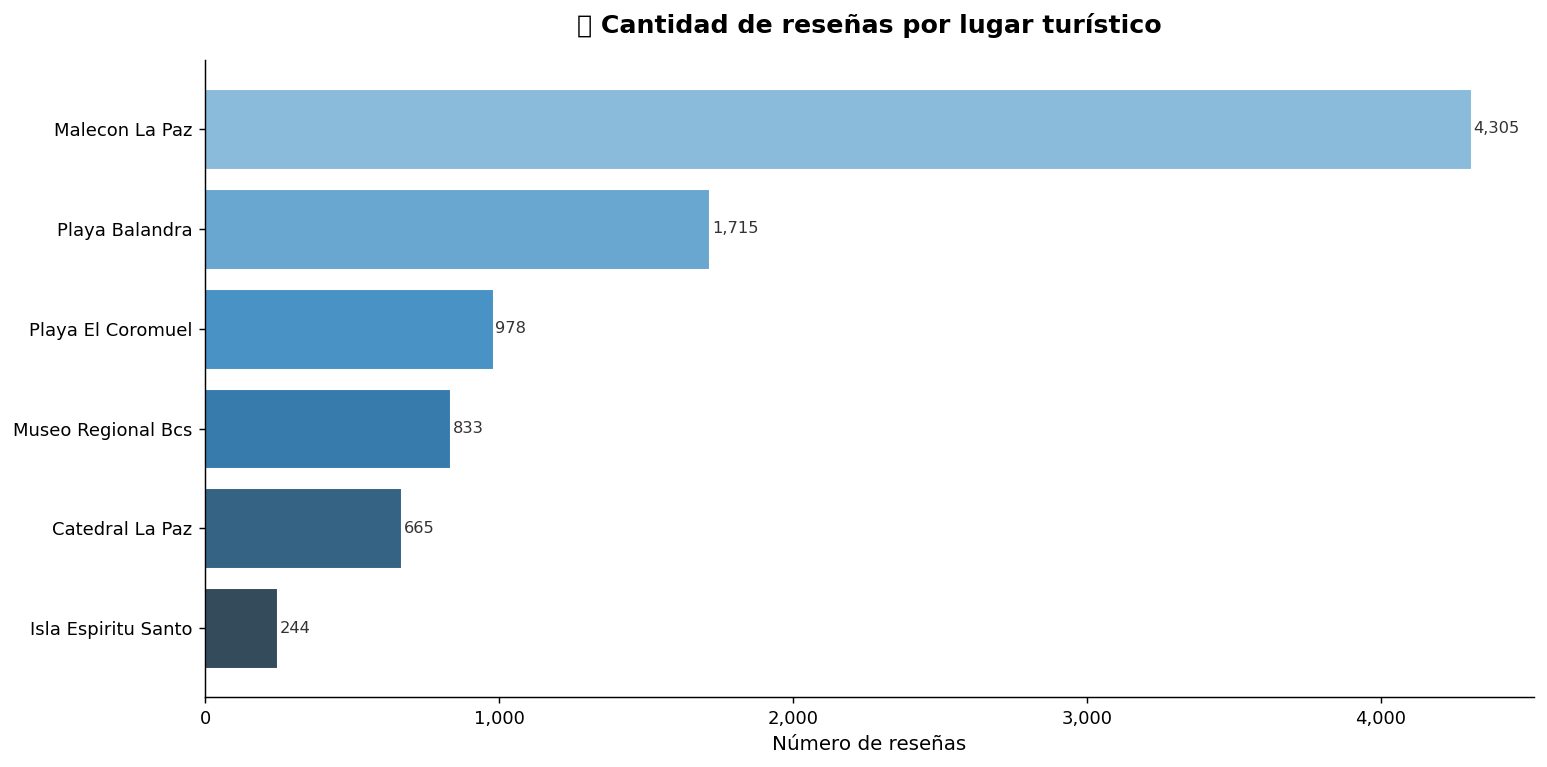

                     # reseñas
lugar                         
malecon_la_paz            4305
playa_balandra            1715
playa_el_coromuel          978
museo_regional_bcs         833
catedral_la_paz            665
isla_espiritu_santo        244


In [10]:
# ── CONTEO DE RESEÑAS POR LUGAR ───────────────────────────────────────────────
# Ordenamos de mayor a menor para facilitar la comparación visual.
conteo_lugar = (
    df['lugar']
    .value_counts()
    .sort_values(ascending=False)
)

# Formateamos los nombres de los lugares para la gráfica
etiquetas = [nombre.replace('_', ' ').title() for nombre in conteo_lugar.index]

fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.barh(
    etiquetas[::-1],               # invertimos para que el mayor quede arriba
    conteo_lugar.values[::-1],
    color=sns.color_palette('Blues_d', len(conteo_lugar))[::-1],
    edgecolor='white', linewidth=0.6
)

# Etiqueta de valor al final de cada barra
for bar, val in zip(bars, conteo_lugar.values[::-1]):
    ax.text(bar.get_width() + 10, bar.get_y() + bar.get_height() / 2,
            f'{val:,}', va='center', fontsize=9, color='#333')

ax.set_xlabel('Número de reseñas', fontsize=11)
ax.set_title('📍 Cantidad de reseñas por lugar turístico', fontsize=14, fontweight='bold', pad=15)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.tight_layout()
plt.savefig('01_resenas_por_lugar.png', bbox_inches='tight')
plt.show()
print(conteo_lugar.to_frame('# reseñas'))

### 1.3 · Distribución general de calificaciones (estrellas)

C:\Users\default.LAPTOP-KBBOSBHD\AppData\Local\Temp\ipykernel_40972\1869976093.py:37: UserWarning: Glyph 11088 (\N{WHITE MEDIUM STAR}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\default.LAPTOP-KBBOSBHD\AppData\Local\Temp\ipykernel_40972\1869976093.py:38: UserWarning: Glyph 11088 (\N{WHITE MEDIUM STAR}) missing from font(s) DejaVu Sans.
  plt.savefig('02_distribucion_estrellas.png', bbox_inches='tight')
c:\Users\default.LAPTOP-KBBOSBHD\Documents\visualizacion_de_la_informacion\Analisis_destino_turismo\venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 11088 (\N{WHITE MEDIUM STAR}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


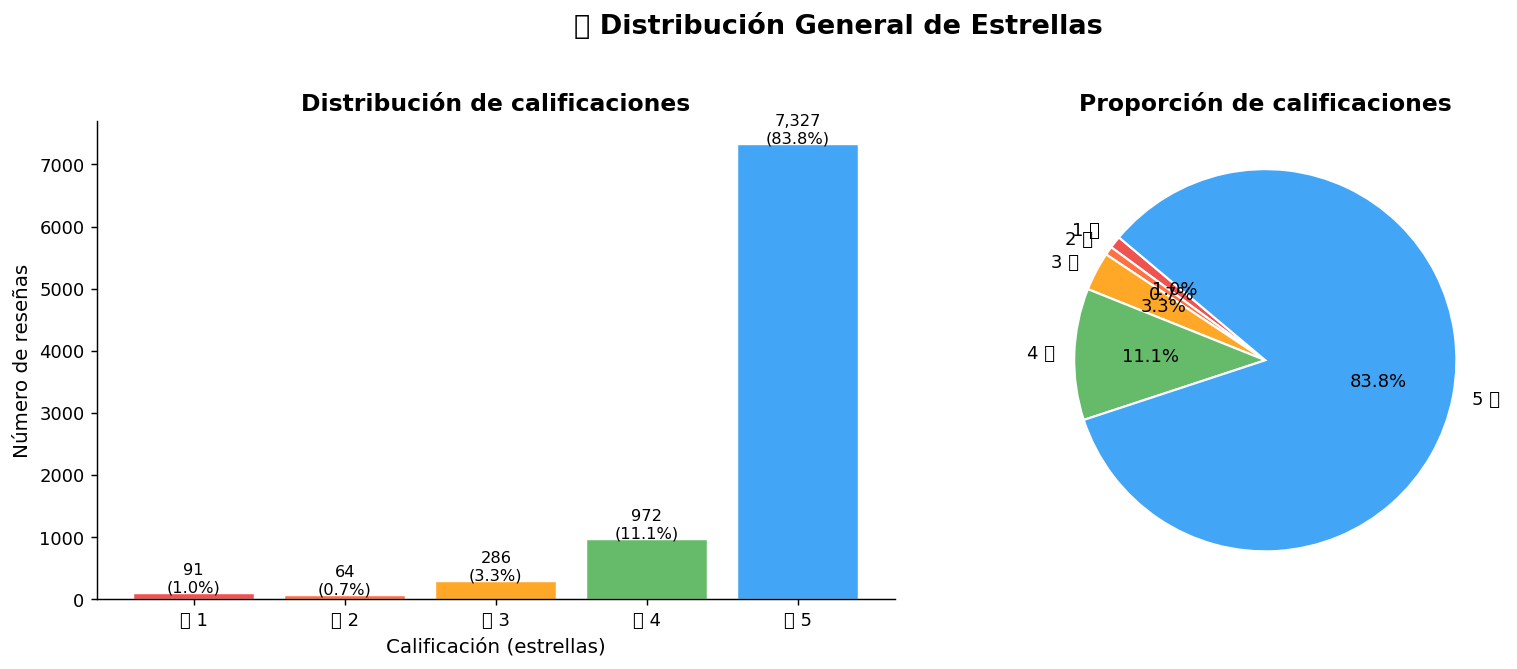

Media global: 4.76 ★
Mediana global: 5.0 ★


In [11]:
# ── DISTRIBUCIÓN DE ESTRELLAS ─────────────────────────────────────────────────
# Usamos un countplot para mostrar la frecuencia de cada puntuación.
dist_estrellas = df['estrellas'].value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# — Gráfico de barras —
colores = ['#EF5350','#FF7043','#FFA726','#66BB6A','#42A5F5']
axes[0].bar(
    dist_estrellas.index,
    dist_estrellas.values,
    color=colores,
    edgecolor='white', linewidth=0.8
)
for x, y in zip(dist_estrellas.index, dist_estrellas.values):
    pct = y / len(df) * 100
    axes[0].text(x, y + 20, f'{y:,}\n({pct:.1f}%)', ha='center', fontsize=9)

axes[0].set_xlabel('Calificación (estrellas)', fontsize=11)
axes[0].set_ylabel('Número de reseñas', fontsize=11)
axes[0].set_title('Distribución de calificaciones', fontsize=13, fontweight='bold')
axes[0].set_xticks([1, 2, 3, 4, 5])
axes[0].set_xticklabels(['⭐ 1','⭐ 2','⭐ 3','⭐ 4','⭐ 5'])

# — Gráfico de pastel —
axes[1].pie(
    dist_estrellas.values,
    labels=[f'{i} ⭐' for i in dist_estrellas.index],
    autopct='%1.1f%%',
    colors=colores,
    startangle=140,
    wedgeprops={'edgecolor':'white','linewidth':1.2}
)
axes[1].set_title('Proporción de calificaciones', fontsize=13, fontweight='bold')

plt.suptitle('⭐ Distribución General de Estrellas', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('02_distribucion_estrellas.png', bbox_inches='tight')
plt.show()

print(f"Media global: {df['estrellas'].mean():.2f} ★")
print(f"Mediana global: {df['estrellas'].median():.1f} ★")

### 1.4 · Análisis bivariado — Promedio de estrellas por lugar

,Lugar,Media ⭐,Mediana ⭐,# Reseñas
0,Isla Espiritu Santo,4.92,5.0,244
1,Malecon La Paz,4.85,5.0,"4,305"
2,Playa Balandra,4.78,5.0,"1,715"
3,Museo Regional Bcs,4.63,5.0,833
4,Playa El Coromuel,4.62,5.0,978
5,Catedral La Paz,4.45,5.0,665


C:\Users\default.LAPTOP-KBBOSBHD\AppData\Local\Temp\ipykernel_40972\3585667495.py:48: UserWarning: Glyph 127942 (\N{TROPHY}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\default.LAPTOP-KBBOSBHD\AppData\Local\Temp\ipykernel_40972\3585667495.py:48: UserWarning: Glyph 11088 (\N{WHITE MEDIUM STAR}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\default.LAPTOP-KBBOSBHD\AppData\Local\Temp\ipykernel_40972\3585667495.py:49: UserWarning: Glyph 127942 (\N{TROPHY}) missing from font(s) DejaVu Sans.
  plt.savefig('03_promedio_estrellas_lugar.png', bbox_inches='tight')
C:\Users\default.LAPTOP-KBBOSBHD\AppData\Local\Temp\ipykernel_40972\3585667495.py:49: UserWarning: Glyph 11088 (\N{WHITE MEDIUM STAR}) missing from font(s) DejaVu Sans.
  plt.savefig('03_promedio_estrellas_lugar.png', bbox_inches='tight')
c:\Users\default.LAPTOP-KBBOSBHD\Documents\visualizacion_de_la_informacion\Analisis_destino_turismo\venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWar

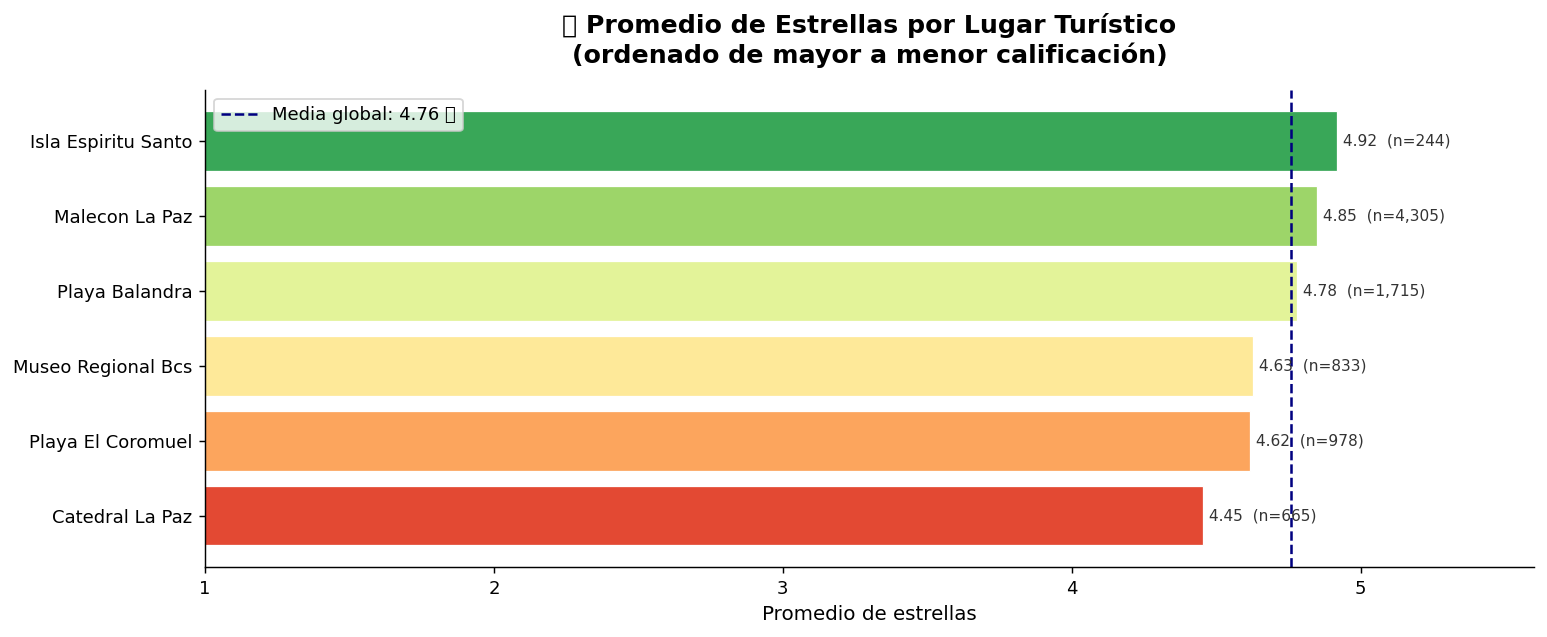

In [12]:
# ── PROMEDIO DE ESTRELLAS POR LUGAR (bivariado) ───────────────────────────────
# Calculamos media, mediana y número de reseñas para un análisis más robusto.
bivariado = (
    df.groupby('lugar')['estrellas']
    .agg(media='mean', mediana='median', n_resenas='count')
    .sort_values('media', ascending=False)
    .reset_index()
)
bivariado['lugar_fmt'] = bivariado['lugar'].str.replace('_', ' ').str.title()

display(bivariado[['lugar_fmt','media','mediana','n_resenas']]
        .rename(columns={'lugar_fmt':'Lugar','media':'Media ⭐',
                          'mediana':'Mediana ⭐','n_resenas':'# Reseñas'})
        .style.background_gradient(subset=['Media ⭐'], cmap='RdYlGn')
        .format({'Media ⭐': '{:.2f}', 'Mediana ⭐': '{:.1f}', '# Reseñas': '{:,}'}))

# ── GRÁFICA PRINCIPAL ─────────────────────────────────────────────────────────
n = len(bivariado)
# Color degradado: verde para los mejor evaluados, rojo para los peor evaluados
colores_grad = sns.color_palette('RdYlGn', n)[::-1]

fig, ax = plt.subplots(figsize=(12, max(5, n * 0.55)))

bars = ax.barh(
    bivariado['lugar_fmt'][::-1],
    bivariado['media'][::-1],
    color=list(reversed(colores_grad)),
    edgecolor='white', linewidth=0.7
)

# Línea de referencia: media global
media_global = df['estrellas'].mean()
ax.axvline(media_global, color='navy', linestyle='--', linewidth=1.4,
           label=f'Media global: {media_global:.2f} ⭐')

# Etiquetas de valor y número de reseñas
for bar, (_, row) in zip(bars, bivariado[::-1].iterrows()):
    ax.text(bar.get_width() + 0.02,
            bar.get_y() + bar.get_height() / 2,
            f"{row['media']:.2f}  (n={row['n_resenas']:,})",
            va='center', fontsize=8.5, color='#333')

ax.set_xlim(1, 5.6)
ax.set_xlabel('Promedio de estrellas', fontsize=11)
ax.set_title('🏆 Promedio de Estrellas por Lugar Turístico\n(ordenado de mayor a menor calificación)',
             fontsize=14, fontweight='bold', pad=15)
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig('03_promedio_estrellas_lugar.png', bbox_inches='tight')
plt.show()

C:\Users\default.LAPTOP-KBBOSBHD\AppData\Local\Temp\ipykernel_40972\3272281510.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\default.LAPTOP-KBBOSBHD\AppData\Local\Temp\ipykernel_40972\3272281510.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(etiq, rotation=35, ha='right', fontsize=9)
C:\Users\default.LAPTOP-KBBOSBHD\AppData\Local\Temp\ipykernel_40972\3272281510.py:20: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\default.LAPTOP-KBBOSBHD\AppData\Local\Temp\ipykernel_40972\3272281510.py:21: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.savefig('04_boxplot_estrellas_lugar.png', bbox_inches='tight')
c:\Users\default.LAPTOP-K

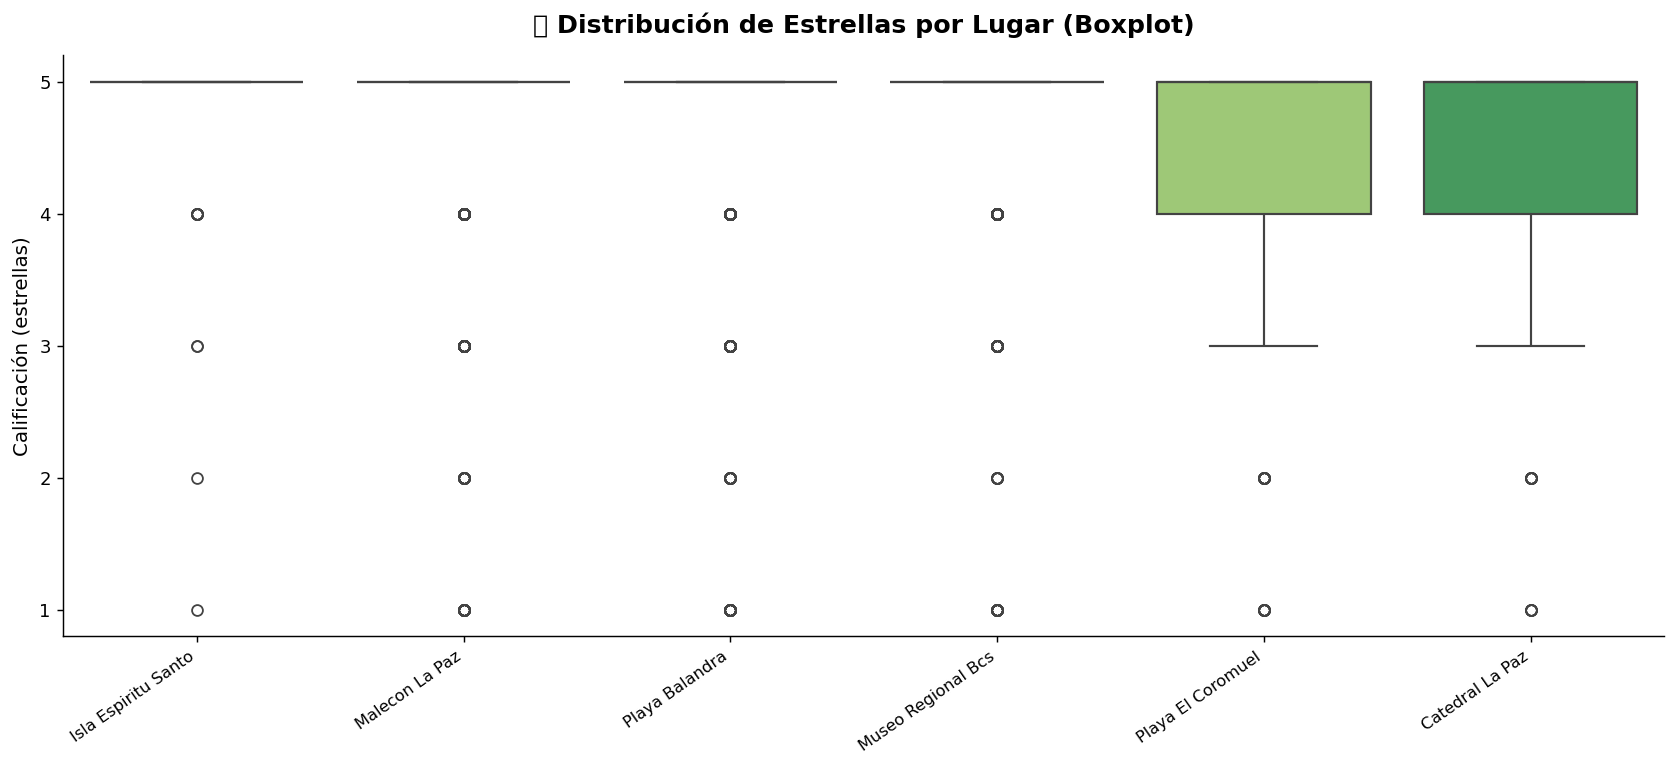

In [13]:
# ── BOXPLOT COMPLEMENTARIO: distribución completa por lugar ───────────────────
# El boxplot revela la dispersión real, no solo el promedio.
orden = bivariado['lugar'].tolist()   # orden por media descendente
etiq  = [l.replace('_',' ').title() for l in orden]

fig, ax = plt.subplots(figsize=(13, 6))
sns.boxplot(
    data=df,
    x='lugar', y='estrellas',
    order=orden,
    palette='RdYlGn',
    linewidth=1.2,
    ax=ax
)
ax.set_xticklabels(etiq, rotation=35, ha='right', fontsize=9)
ax.set_xlabel('')
ax.set_ylabel('Calificación (estrellas)', fontsize=11)
ax.set_title('📊 Distribución de Estrellas por Lugar (Boxplot)', fontsize=14, fontweight='bold', pad=12)
ax.set_yticks([1,2,3,4,5])
plt.tight_layout()
plt.savefig('04_boxplot_estrellas_lugar.png', bbox_inches='tight')
plt.show()

---
## PARTE 2 — Limpieza y Lematización del Texto

### 2.1 · Función de limpieza + lematización (stemming)

In [21]:
# ── RECURSOS NLTK ─────────────────────────────────────────────────────────────
# Stopwords en español (palabras vacías sin valor semántico).
STOP_ES = set(stopwords.words('spanish'))
STOP_EN = set(stopwords.words('english'))


# Añadimos manualmente stopwords frecuentes en reseñas turísticas
# que no aportan información discriminante:
STOP_EXTRA = {
    'lugar', 'sitio', 'visitar', 'vez', 'bien', 'muy', 'mas',
    'si', 'solo', 'tambien', 'puede', 'ser', 'ver', 'ir',
    'poco', 'todo', 'toda', 'todos', 'es', 'la', 'el', 'los', 'las',
    'de', 'en', 'un', 'una', 'del', 'al', 'por', 'con', 'que',
    'se', 'su', 'sus', 'le', 'lo', 'nos', 'para', 'como', 'pero',
    'hay', 'tiene', 'son', 'fue', 'gran', 'este', 'esta',
}
STOP_TOTAL = STOP_ES | STOP_EN | STOP_EXTRA

# Snowball Stemmer: reduce palabras a su raíz morfológica
# (p.ej. "hermoso", "hermosa", "hermosas" → "herm")
stemmer = SnowballStemmer('spanish')
stemmer_en = SnowballStemmer('english')
# ── FUNCIÓN DE LIMPIEZA ───────────────────────────────────────────────────────
def limpiar_texto(texto: str) -> str:
    """
    Pipeline de preprocesamiento de texto:
      1. Convierte a minúsculas.
      2. Elimina acentos y caracteres especiales (sustituye letras acentuadas).
      3. Elimina números y signos de puntuación.
      4. Tokeniza (divide en palabras).
      5. Elimina stopwords.
      6. Aplica stemming (lematización por raíz).
    """
    if not isinstance(texto, str):
        return ''

    # 1. Minúsculas
    texto = texto.lower()

    # 2. Reemplazar letras acentuadas (para uniformizar tokens en español)
    reemplazos = str.maketrans(
        'áéíóúüàèìòùâêîôûäëïöü',
        'aeiouuaeiouaeiouaeiou'
    )
    texto = texto.translate(reemplazos)

    # 3. Eliminar caracteres no alfabéticos (números, puntuación, emojis, etc.)
    texto = re.sub(r'[^a-z\s]', ' ', texto)

    # 4. Tokenizar por espacios
    tokens = texto.split()

    # 5. Filtrar stopwords y palabras cortas (< 3 caracteres)
    tokens = [t for t in tokens if t not in STOP_TOTAL and len(t) >= 3]

    # 6. Stemming (raíz morfológica)
    tokens = [stemmer.stem(t) for t in tokens]
    tokens = [stemmer_en.stem(t) for t in tokens]

    return ' '.join(tokens)

# ── PRUEBA RÁPIDA DE LA FUNCIÓN ───────────────────────────────────────────────
ejemplo = "¡Excelente lugar para visitar! Muy bonito y bien conservado. Recomendado 100%."
print(f'ORIGINAL : {ejemplo}')
print(f'LIMPIO   : {limpiar_texto(ejemplo)}')

ORIGINAL : ¡Excelente lugar para visitar! Muy bonito y bien conservado. Recomendado 100%.
LIMPIO   : excel bonit conserv recomend


### 2.2 · Aplicación al DataFrame → columna `texto_limpio`

In [22]:
# ── APLICAR LIMPIEZA A TODO EL CORPUS ────────────────────────────────────────
# Dependiendo del tamaño del dataset esto puede tomar ~10-30 segundos.
print('Procesando texto... (puede tardar unos segundos)')
df['texto_limpio'] = df['texto'].apply(limpiar_texto)

# Eliminamos filas donde el texto quedó vacío tras la limpieza
df = df[df['texto_limpio'].str.strip() != ''].copy()
df.reset_index(drop=True, inplace=True)

print(f'✅ Texto limpio generado. Filas finales: {len(df):,}')

# Comparación de muestra
df[['texto', 'texto_limpio']].sample(5, random_state=42)

Procesando texto... (puede tardar unos segundos)
✅ Texto limpio generado. Filas finales: 8,726


,texto,texto_limpio
1057,"Buen lugar para caminar, correr etc.",buen camin corr etc
8115,"la información que se brinda es muy buena, tú ...",inform brind buen hac recorr inform leyend cad...
3992,El paraíso en la tierra,parai tierr
3418,Nice great family place need to go..,nic great famili plac need
5111,Espectacular,espectacul


C:\Users\default.LAPTOP-KBBOSBHD\AppData\Local\Temp\ipykernel_40972\18495178.py:23: UserWarning: Glyph 128207 (\N{STRAIGHT RULER}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\default.LAPTOP-KBBOSBHD\AppData\Local\Temp\ipykernel_40972\18495178.py:24: UserWarning: Glyph 128207 (\N{STRAIGHT RULER}) missing from font(s) DejaVu Sans.
  plt.savefig('05_longitud_texto.png', bbox_inches='tight')
c:\Users\default.LAPTOP-KBBOSBHD\Documents\visualizacion_de_la_informacion\Analisis_destino_turismo\venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128207 (\N{STRAIGHT RULER}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


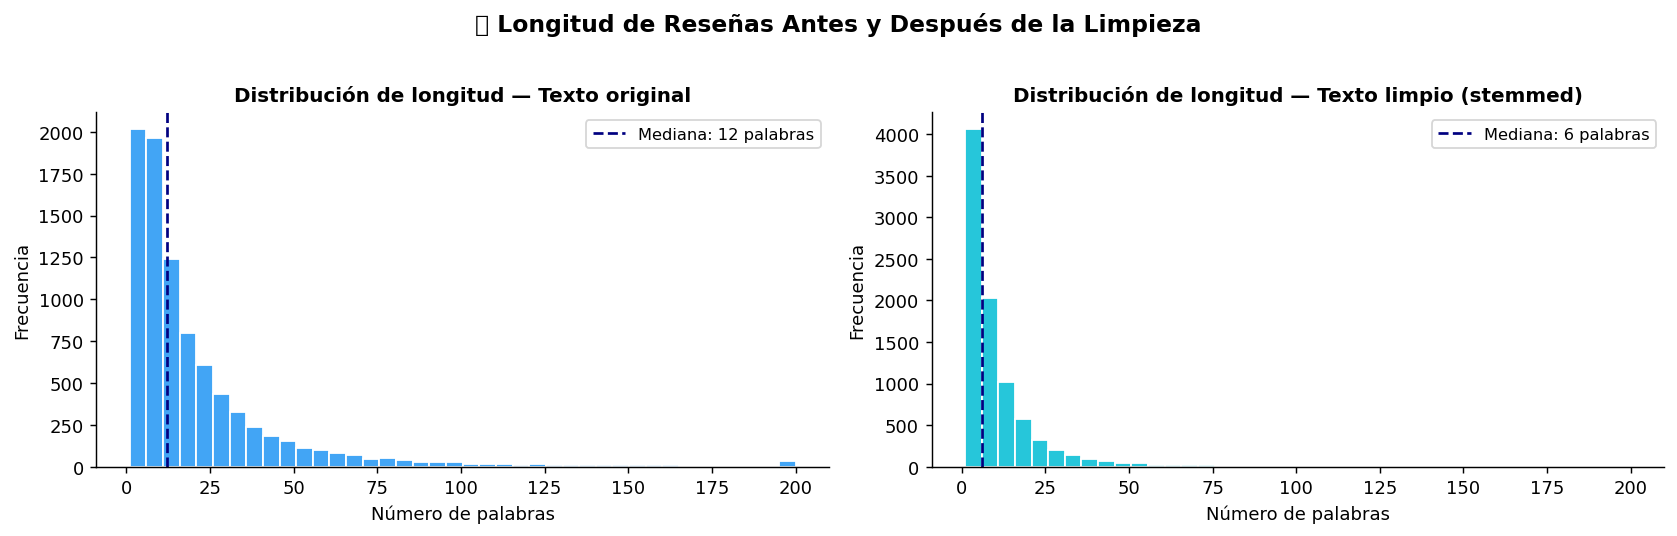

Promedio palabras ORIGINAL : 21.0
Promedio palabras LIMPIO   : 10.4


In [23]:
# ── ESTADÍSTICA DE LONGITUD DEL TEXTO ────────────────────────────────────────
# Analizamos cuántas palabras tiene cada reseña antes y después de la limpieza.
df['n_palabras_orig']   = df['texto'].apply(lambda x: len(str(x).split()))
df['n_palabras_limpio'] = df['texto_limpio'].apply(lambda x: len(str(x).split()))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col, titulo, color in zip(
    axes,
    ['n_palabras_orig', 'n_palabras_limpio'],
    ['Texto original', 'Texto limpio (stemmed)'],
    ['#42A5F5', '#26C6DA']
):
    ax.hist(df[col].clip(upper=200), bins=40, color=color, edgecolor='white')
    ax.set_title(f'Distribución de longitud — {titulo}', fontsize=11, fontweight='bold')
    ax.set_xlabel('Número de palabras')
    ax.set_ylabel('Frecuencia')
    ax.axvline(df[col].median(), color='navy', linestyle='--',
               label=f'Mediana: {df[col].median():.0f} palabras')
    ax.legend(fontsize=9)

plt.suptitle('📏 Longitud de Reseñas Antes y Después de la Limpieza',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('05_longitud_texto.png', bbox_inches='tight')
plt.show()

print(f"Promedio palabras ORIGINAL : {df['n_palabras_orig'].mean():.1f}")
print(f"Promedio palabras LIMPIO   : {df['n_palabras_limpio'].mean():.1f}")

---
## PARTE 3 — Análisis de Frecuencias y Nube de Palabras

### 3.1 · Top 20 palabras más frecuentes en el corpus

,palabra,frecuencia
0,play,1740
1,bonit,1484
2,hermo,1392
3,malecon,1045
4,paz,1012
5,tranquil,894
6,limpi,861
7,excel,832
8,camin,765
9,buen,712


C:\Users\default.LAPTOP-KBBOSBHD\AppData\Local\Temp\ipykernel_40972\3408364799.py:36: UserWarning: Glyph 128292 (\N{INPUT SYMBOL FOR LATIN LETTERS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\default.LAPTOP-KBBOSBHD\AppData\Local\Temp\ipykernel_40972\3408364799.py:37: UserWarning: Glyph 128292 (\N{INPUT SYMBOL FOR LATIN LETTERS}) missing from font(s) DejaVu Sans.
  plt.savefig('06_top20_palabras.png', bbox_inches='tight')
c:\Users\default.LAPTOP-KBBOSBHD\Documents\visualizacion_de_la_informacion\Analisis_destino_turismo\venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128292 (\N{INPUT SYMBOL FOR LATIN LETTERS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


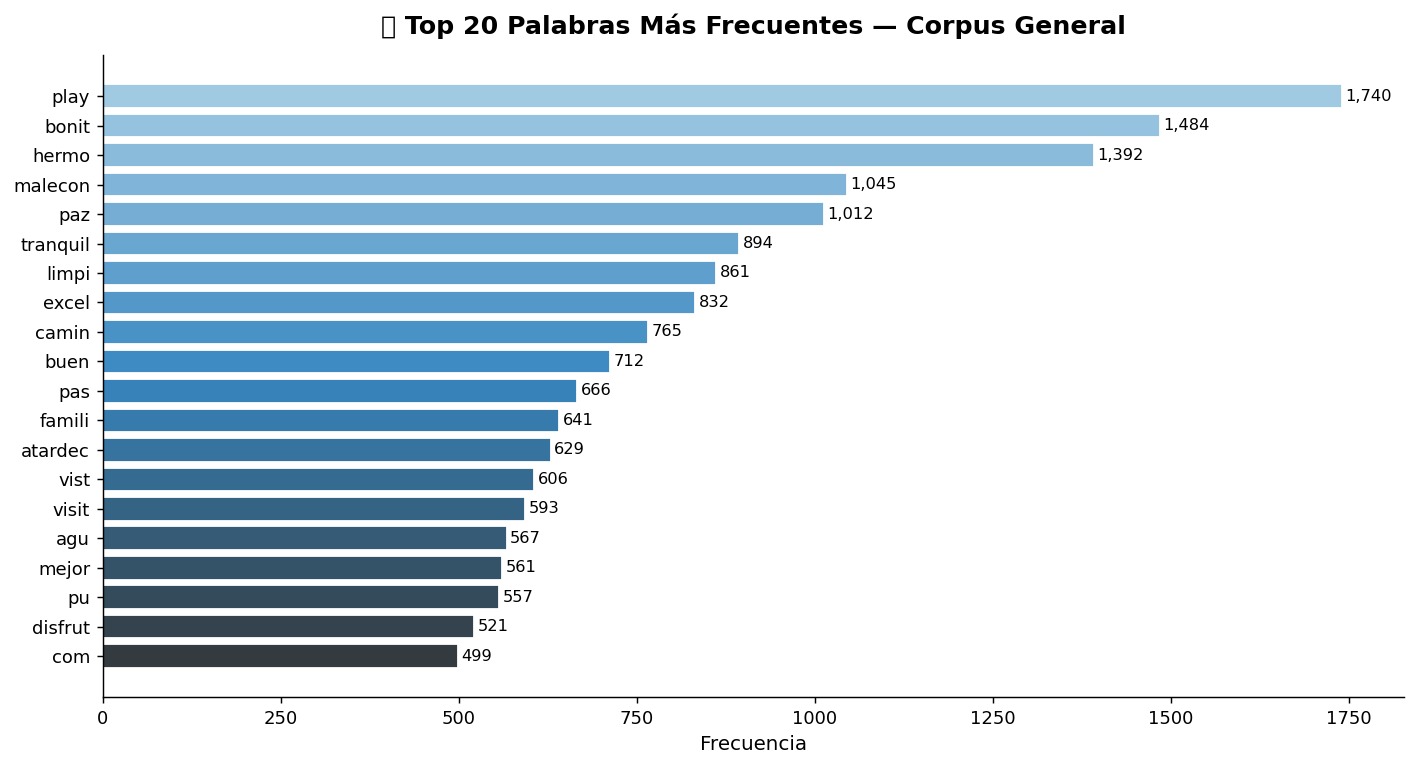

In [24]:
# ── FUNCIÓN AUXILIAR: obtener frecuencias de tokens ──────────────────────────
def obtener_frecuencias(serie_texto: pd.Series, top_n: int = 20) -> pd.DataFrame:
    """
    Concatena todos los textos limpios, tokeniza y devuelve
    un DataFrame con las `top_n` palabras más frecuentes.
    """
    corpus = ' '.join(serie_texto.dropna().tolist())
    tokens = corpus.split()
    freq   = Counter(tokens)
    return (
        pd.DataFrame(freq.most_common(top_n), columns=['palabra', 'frecuencia'])
    )

# ── TOP 20 GLOBAL ─────────────────────────────────────────────────────────────
top20 = obtener_frecuencias(df['texto_limpio'], top_n=20)
display(top20)

# ── GRÁFICA DE BARRAS ─────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(11, 6))
colores_freq = sns.color_palette('Blues_d', 20)

bars = ax.barh(
    top20['palabra'][::-1],
    top20['frecuencia'][::-1],
    color=list(reversed(colores_freq)),
    edgecolor='white'
)

for bar, val in zip(bars, top20['frecuencia'][::-1]):
    ax.text(bar.get_width() + 5, bar.get_y() + bar.get_height() / 2,
            f'{val:,}', va='center', fontsize=9)

ax.set_xlabel('Frecuencia', fontsize=11)
ax.set_title('🔤 Top 20 Palabras Más Frecuentes — Corpus General',
             fontsize=14, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig('06_top20_palabras.png', bbox_inches='tight')
plt.show()

### 3.2 · Nube de palabras general

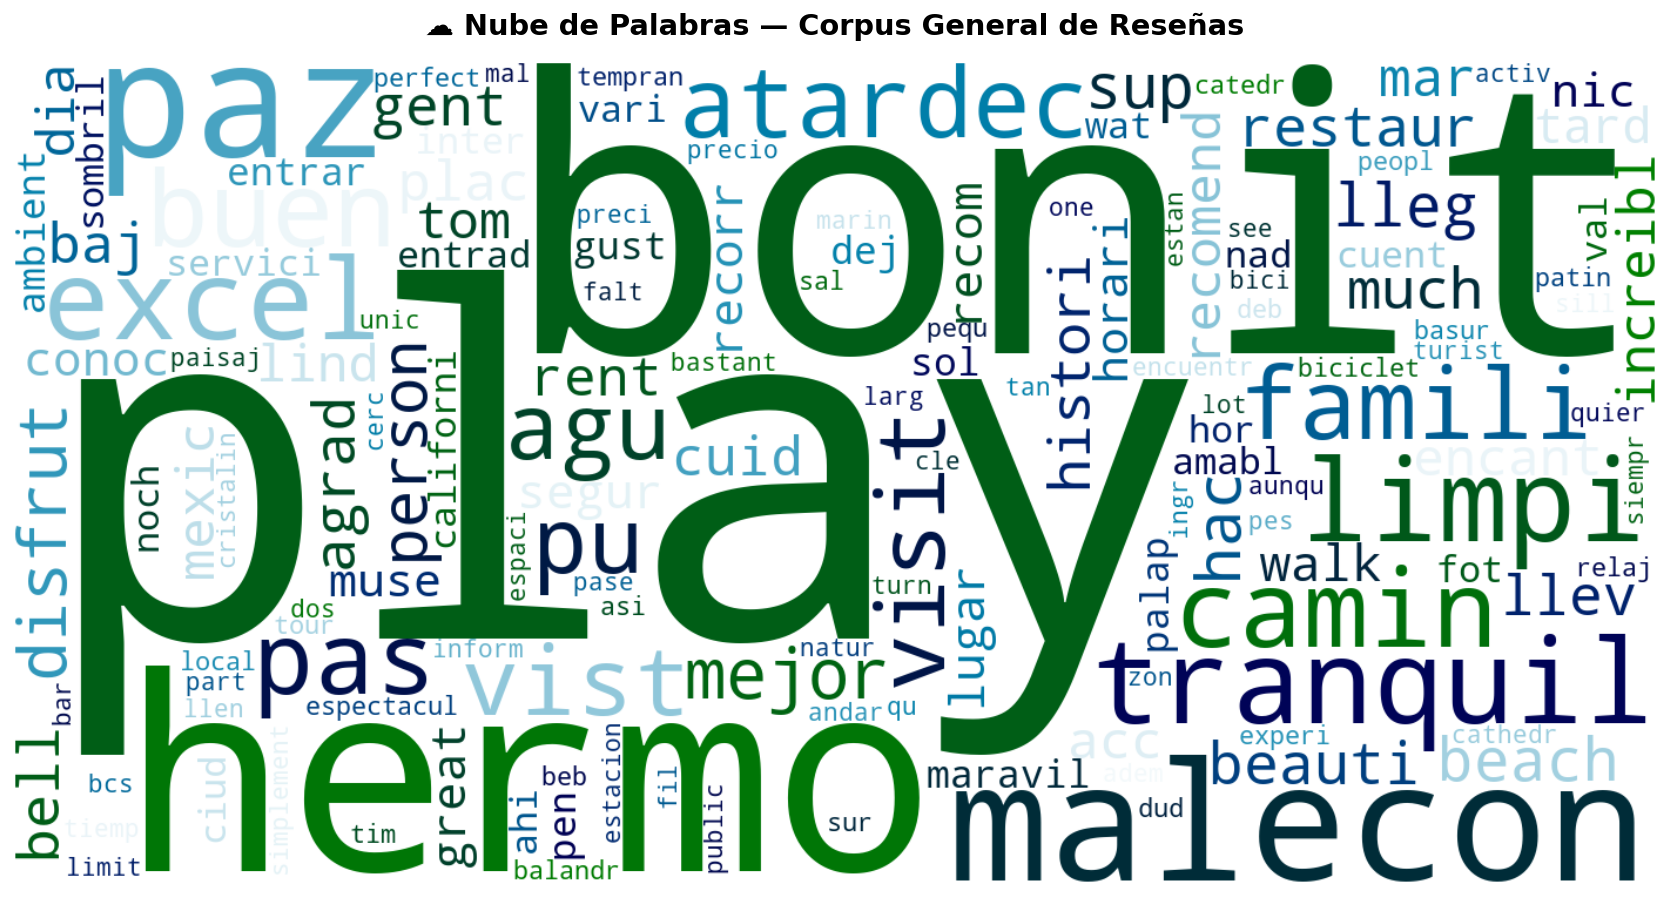

✅ Nube de palabras general generada.


In [25]:
# ── NUBE DE PALABRAS GENERAL ──────────────────────────────────────────────────
# Concatenamos todo el corpus limpio en un solo string.
corpus_general = ' '.join(df['texto_limpio'].tolist())

wc_general = WordCloud(
    width           = 1400,
    height          = 700,
    background_color= 'white',
    colormap        = 'ocean',       # paleta de colores azulada (marino)
    max_words       = 150,
    collocations    = False,         # evita que pares de palabras cuenten doble
    random_state    = 42
).generate(corpus_general)

fig, ax = plt.subplots(figsize=(14, 7))
ax.imshow(wc_general, interpolation='bilinear')
ax.axis('off')
ax.set_title('☁️ Nube de Palabras — Corpus General de Reseñas',
             fontsize=16, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig('07_wordcloud_general.png', bbox_inches='tight', dpi=150)
plt.show()
print('✅ Nube de palabras general generada.')

### 3.3 · Nubes de palabras por sentimiento (reseñas positivas vs. negativas)

Reseñas positivas (4-5 ⭐): 8,288  (95.0%)
Reseñas negativas (1-3 ⭐): 438  (5.0%)


C:\Users\default.LAPTOP-KBBOSBHD\AppData\Local\Temp\ipykernel_40972\2415410655.py:32: UserWarning: Glyph 11088 (\N{WHITE MEDIUM STAR}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\default.LAPTOP-KBBOSBHD\AppData\Local\Temp\ipykernel_40972\2415410655.py:33: UserWarning: Glyph 11088 (\N{WHITE MEDIUM STAR}) missing from font(s) DejaVu Sans.
  plt.savefig('08_wordclouds_sentimiento.png', bbox_inches='tight', dpi=150)
c:\Users\default.LAPTOP-KBBOSBHD\Documents\visualizacion_de_la_informacion\Analisis_destino_turismo\venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 11088 (\N{WHITE MEDIUM STAR}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


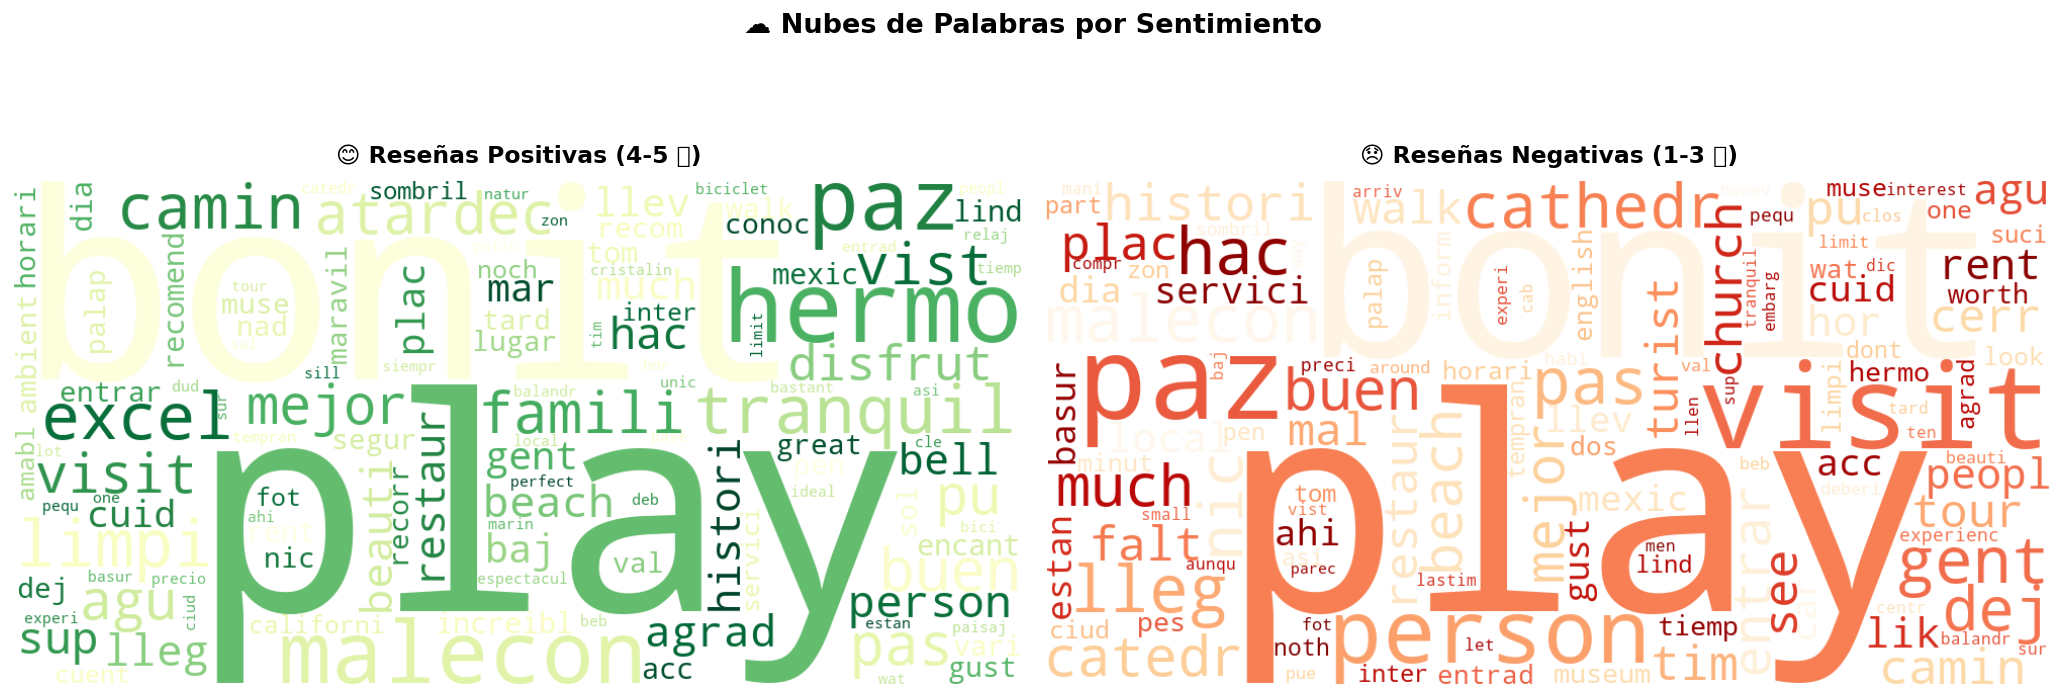

In [26]:
# ── SEGMENTACIÓN POR SENTIMIENTO ─────────────────────────────────────────────
# Positivas : 4 y 5 estrellas
# Negativas : 1, 2 y 3 estrellas
df_pos = df[df['estrellas'] >= 4].copy()
df_neg = df[df['estrellas'] <= 3].copy()

print(f'Reseñas positivas (4-5 ⭐): {len(df_pos):,}  ({len(df_pos)/len(df)*100:.1f}%)')
print(f'Reseñas negativas (1-3 ⭐): {len(df_neg):,}  ({len(df_neg)/len(df)*100:.1f}%)')

corpus_pos = ' '.join(df_pos['texto_limpio'].tolist())
corpus_neg = ' '.join(df_neg['texto_limpio'].tolist())

# ── GENERAR NUBES ─────────────────────────────────────────────────────────────
def generar_wordcloud(corpus, colormap, titulo, filename, ax):
    wc = WordCloud(
        width=1000, height=500,
        background_color='white',
        colormap=colormap,
        max_words=120,
        collocations=False,
        random_state=42
    ).generate(corpus)
    ax.imshow(wc, interpolation='bilinear')
    ax.axis('off')
    ax.set_title(titulo, fontsize=13, fontweight='bold', pad=10)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
generar_wordcloud(corpus_pos, 'YlGn',  '😊 Reseñas Positivas (4-5 ⭐)', '08a', axes[0])
generar_wordcloud(corpus_neg, 'OrRd',  '😞 Reseñas Negativas (1-3 ⭐)', '08b', axes[1])

plt.suptitle('☁️ Nubes de Palabras por Sentimiento', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('08_wordclouds_sentimiento.png', bbox_inches='tight', dpi=150)
plt.show()

C:\Users\default.LAPTOP-KBBOSBHD\AppData\Local\Temp\ipykernel_40972\505484059.py:26: UserWarning: Glyph 11088 (\N{WHITE MEDIUM STAR}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\default.LAPTOP-KBBOSBHD\AppData\Local\Temp\ipykernel_40972\505484059.py:26: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\default.LAPTOP-KBBOSBHD\AppData\Local\Temp\ipykernel_40972\505484059.py:27: UserWarning: Glyph 11088 (\N{WHITE MEDIUM STAR}) missing from font(s) DejaVu Sans.
  plt.savefig('09_top15_pos_vs_neg.png', bbox_inches='tight')
C:\Users\default.LAPTOP-KBBOSBHD\AppData\Local\Temp\ipykernel_40972\505484059.py:27: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.savefig('09_top15_pos_vs_neg.png', bbox_inches='tight')
c:\Users\default.LAPTOP-KBBOSBHD\Documents\visualizacion_de_la_informacion\Analisis_destino_turismo\venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 12

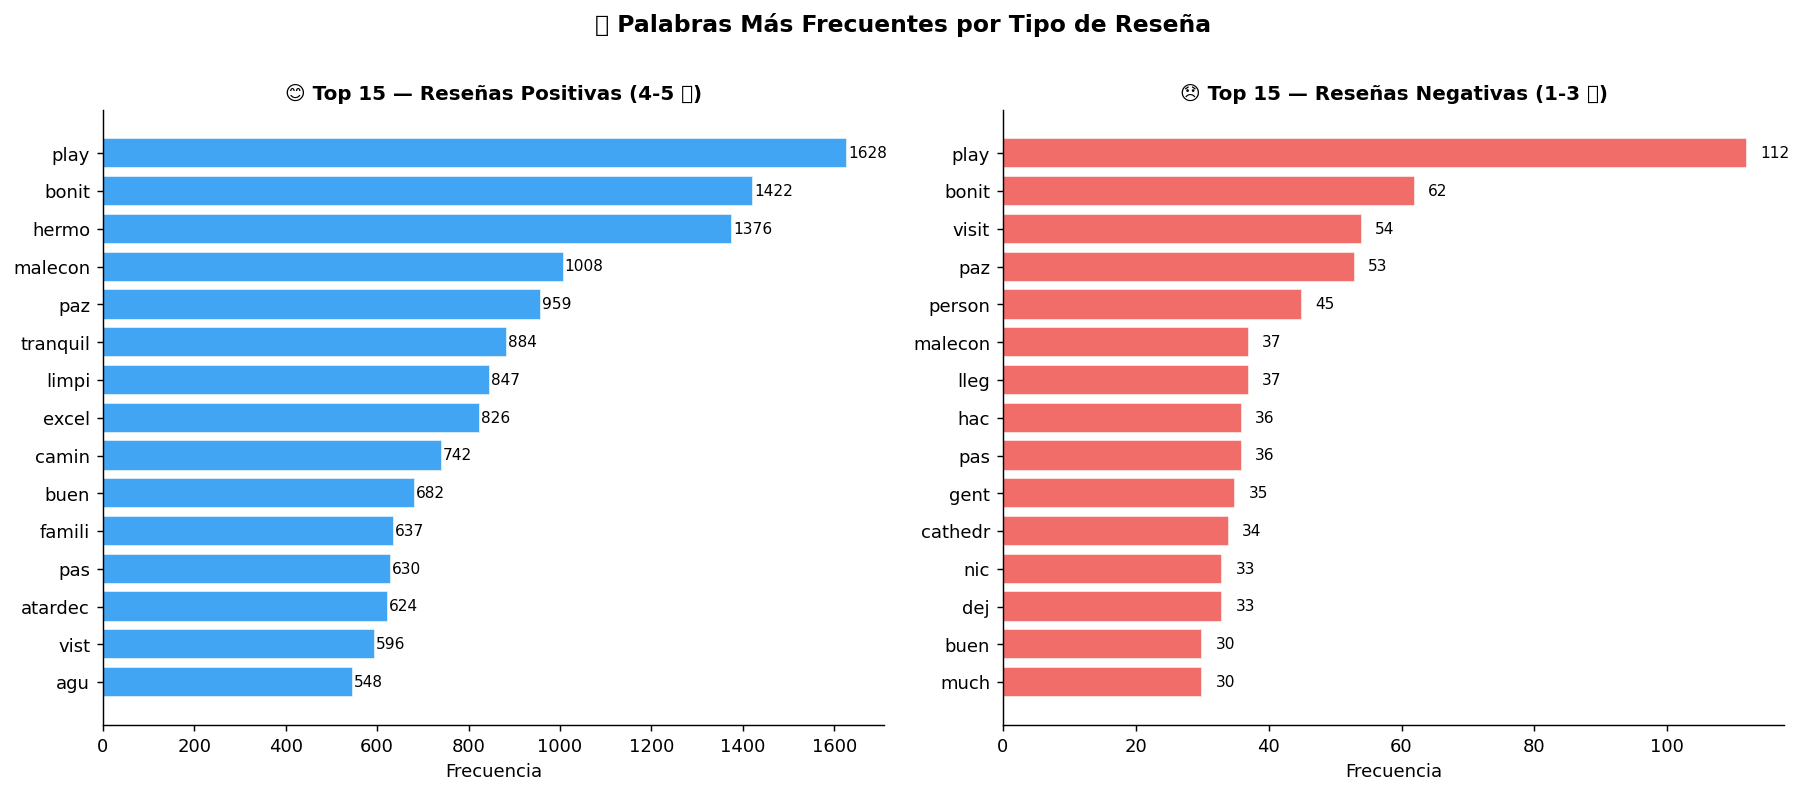

In [27]:
# ── TOP 15 PALABRAS: POSITIVAS vs. NEGATIVAS (comparación lado a lado) ────────
top_pos = obtener_frecuencias(df_pos['texto_limpio'], top_n=15)
top_neg = obtener_frecuencias(df_neg['texto_limpio'], top_n=15)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, top_df, titulo, color in zip(
    axes,
    [top_pos, top_neg],
    ['😊 Top 15 — Reseñas Positivas (4-5 ⭐)', '😞 Top 15 — Reseñas Negativas (1-3 ⭐)'],
    [COLOR_POS, COLOR_NEG]
):
    bars = ax.barh(
        top_df['palabra'][::-1],
        top_df['frecuencia'][::-1],
        color=color, edgecolor='white', alpha=0.85
    )
    for bar, val in zip(bars, top_df['frecuencia'][::-1]):
        ax.text(bar.get_width() + 2, bar.get_y() + bar.get_height() / 2,
                str(val), va='center', fontsize=8.5)
    ax.set_title(titulo, fontsize=11, fontweight='bold')
    ax.set_xlabel('Frecuencia')

plt.suptitle('📊 Palabras Más Frecuentes por Tipo de Reseña',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('09_top15_pos_vs_neg.png', bbox_inches='tight')
plt.show()

In [28]:
# ── PALABRAS EXCLUSIVAS (palabras que aparecen SOLO en positivas o negativas) ─
# Identifica vocabulario diagnóstico de cada sentimiento.
set_pos = set(top_pos['palabra'])
set_neg = set(top_neg['palabra'])

solo_positivas = set_pos - set_neg
solo_negativas = set_neg - set_pos
compartidas    = set_pos & set_neg

print(f'Palabras en TOP15 exclusivas de POSITIVAS : {sorted(solo_positivas)}')
print(f'Palabras en TOP15 exclusivas de NEGATIVAS : {sorted(solo_negativas)}')
print(f'Palabras compartidas en ambos tops        : {sorted(compartidas)}')

Palabras en TOP15 exclusivas de POSITIVAS : ['agu', 'atardec', 'camin', 'excel', 'famili', 'hermo', 'limpi', 'tranquil', 'vist']
Palabras en TOP15 exclusivas de NEGATIVAS : ['cathedr', 'dej', 'gent', 'hac', 'lleg', 'much', 'nic', 'person', 'visit']
Palabras compartidas en ambos tops        : ['bonit', 'buen', 'malecon', 'pas', 'paz', 'play']


---
## Resumen del Análisis

| Sección | Hallazgo principal |
|---------|--------------------|
| **Distribución de lugares** | El dataset no está balanceado; algunos lugares tienen muchas más reseñas que otros. |
| **Distribución de estrellas** | La gran mayoría de reseñas son positivas (4-5 ⭐), lo cual es típico en plataformas de turismo. |
| **Bivariado lugar-estrellas** | Se identifican los lugares mejor y peor calificados; el boxplot muestra la dispersión real. |
| **Limpieza de texto** | Se redujo significativamente la longitud promedio eliminando stopwords y aplicando stemming. |
| **Frecuencias globales** | Las raíces morfológicas más frecuentes reflejan los temas centrales de las reseñas. |
| **Nube de palabras** | Visualización intuitiva del vocabulario predominante en el corpus. |
| **Pos vs. Neg** | El vocabulario varía entre sentimientos; las palabras exclusivas de negativos son puntos de mejora. |

**Próximos pasos sugeridos:**
- Análisis de sentimiento con `TextBlob` o `transformers` (BETO en español).
- Topic Modeling con LDA para descubrir temas latentes por lugar.
- Clasificación supervisada de sentimientos usando las estrellas como etiqueta.